# Lab 4 – Klotski with path search

**Problem**: A board of rows x cols cells holds rectangular pieces and some empty cells. A piece can slide
into empty cells. The goal is to move the target piece until it covers the exit cells, on the bottom edge.

**What we look for**: a path, the sequence of moves from the initial board to a board where
the target is on the exit. Each move costs 1, so the best solution is the one with the fewest moves.

**Move rule**: One move = one piece slides through the free cells, by any number of cells (also around a corner),
while all the other pieces stay still. It costs 1.

In [1]:
import heapq
from time import perf_counter

## 1. Reading the instances

`klotski_problems.txt` contains six problems. For each one: the size, the exit columns
on the bottom edge (counted from 0), the name of the target piece, and the board: one token per cell, `.` for an
empty cell; cells with the same token form one rectangular piece.

A piece is stored as its top-left cell and its shape `(height, width)`.

In [2]:
class Problem:
    def __init__(self, name, rows, cols, exit_cols, target, target_shape, start, pieces, rule="slide"):
        self.name = name
        self.rows = rows
        self.cols = cols
        self.exit_cols = exit_cols
        self.target = target
        self.target_shape = target_shape
        self.start = start
        self.pieces = pieces
        self.rule = rule


def with_rule(problem, rule):
    """A copy of the problem with another move rule."""
    return Problem(problem.name, problem.rows, problem.cols, problem.exit_cols, problem.target,
                   problem.target_shape, problem.start, problem.pieces, rule)


def read_problems(path):
    file = open(path, encoding="utf-8")
    lines = file.read().splitlines()
    file.close()
    problems = []
    i = 0
    while i < len(lines):
        line = lines[i].strip()
        if not line.startswith("problem"):
            i = i + 1
            continue
        name = line.split()[1]
        size_words = lines[i + 1].split()               # size <rows> <cols>
        rows = int(size_words[1])
        cols = int(size_words[2])
        exit_words = lines[i + 2].split()               # exit bottom <columns>
        exit_cols = []
        for word in exit_words[2:]:
            exit_cols.append(int(word))
        target = lines[i + 3].split()[1]                # target <piece>
        grid = []                                       # the board
        for r in range(rows):
            grid.append(lines[i + 5 + r].split())
        problems.append(make_problem(name, rows, cols, exit_cols, target, grid))
        i = i + 5 + rows + 1
    return problems


def make_problem(name, rows, cols, exit_cols, target, grid):
    cells = {}                                       # piece name -> list of its cells
    for r in range(rows):
        for c in range(cols):
            token = grid[r][c]
            if token != ".":
                if token not in cells:
                    cells[token] = []
                cells[token].append((r, c))

    pieces = {}                                      # piece name -> (top-left cell, shape)
    for piece in cells:
        first_row = rows
        last_row = -1
        first_col = cols
        last_col = -1
        for (r, c) in cells[piece]:
            if r < first_row:
                first_row = r
            if r > last_row:
                last_row = r
            if c < first_col:
                first_col = c
            if c > last_col:
                last_col = c
        h = last_row - first_row + 1
        w = last_col - first_col + 1
        assert len(cells[piece]) == h * w, name + ": piece " + piece + " is not a rectangle"
        pieces[piece] = ((first_row, first_col), (h, w))

    target_shape = pieces[target][1]
    return Problem(name, rows, cols, exit_cols, target, target_shape, to_state(pieces, target), pieces)

## 2. The state

A state must contain all and only the relevant information: where each piece is. The names of the pieces
are not relevant: two pieces with the same shape are interchangeable, and two boards that differ only by
swapping them are the same situation. So the state forgets the names and keeps, for each piece, its kind
(its shape, or TARGET for the target) and its top-left cell. The tuple is sorted, so that the same board is
always written in the same way.

In [3]:
TARGET = (0, 0)          # kind of the target piece (no real piece has shape 0 x 0)


def to_state(pieces, target):
    state = []
    for piece in pieces:
        position = pieces[piece][0]
        shape = pieces[piece][1]
        if piece == target:
            state.append((TARGET, position))
        else:
            state.append((shape, position))
    state.sort()
    return tuple(state)              # a tuple can be a key of a dictionary


def shape_of(kind, problem):
    if kind == TARGET:
        return problem.target_shape
    return kind


def piece_cells(r, c, h, w):
    """The set of cells covered by a h x w piece whose top-left cell is (r, c)."""
    cells = set()
    for i in range(h):
        for j in range(w):
            cells.add((r + i, c + j))
    return cells


def occupied(state, problem):
    """The set of all the cells covered by the pieces."""
    cells = set()
    for (kind, (r, c)) in state:
        h, w = shape_of(kind, problem)
        for cell in piece_cells(r, c, h, w):
            cells.add(cell)
    return cells

In [4]:
problems = read_problems("klotski_problems.txt")
for p in problems:
    counts = {}                      # shape -> how many pieces have it
    covered = 0                      # cells covered by the pieces
    for piece in p.pieces:
        h, w = p.pieces[piece][1]
        covered = covered + h * w
        if (h, w) not in counts:
            counts[(h, w)] = 0
        counts[(h, w)] = counts[(h, w)] + 1
    empty = p.rows * p.cols - covered
    print(p.name, "board", p.rows, "x", p.cols, "exit columns", p.exit_cols, "target", p.target_shape,
          "pieces", counts, "empty cells", empty)

p01 board 3 x 3 exit columns [1] target (1, 1) pieces {(1, 1): 7} empty cells 2
p02 board 4 x 4 exit columns [1, 2] target (2, 2) pieces {(2, 2): 1, (1, 1): 10} empty cells 2
p03 board 4 x 4 exit columns [1, 2] target (2, 2) pieces {(2, 2): 1, (1, 1): 6, (2, 1): 1, (1, 2): 1} empty cells 2
p04 board 5 x 4 exit columns [1, 2] target (2, 2) pieces {(2, 1): 4, (2, 2): 1, (1, 2): 1, (1, 1): 4} empty cells 2
p05 board 5 x 4 exit columns [1, 2] target (2, 2) pieces {(1, 1): 4, (2, 1): 3, (2, 2): 1, (1, 2): 2} empty cells 2
p06 board 4 x 4 exit columns [1, 2] target (2, 2) pieces {(2, 1): 1, (1, 1): 4, (2, 2): 1, (1, 2): 2} empty cells 2


## 3. The moves

From a state, a move picks one piece and puts it in another position that it can reach by sliding through
empty cells while the other pieces stay still. The positions reachable by a piece are found with a small
flood fill: from its position, try one cell up/down/left/right into free cells, then again from the new
positions, and so on. With the rule "step" only the first ring (one cell) is used.

In [5]:
DIRECTIONS = ((-1, 0), (1, 0), (0, -1), (0, 1))     # up, down, left, right


def one_cell(r, c, h, w, free, problem):
    """The positions reachable by shifting a h x w piece (top-left r, c) by one cell."""
    positions = []
    for (dr, dc) in DIRECTIONS:
        nr = r + dr
        nc = c + dc
        inside = nr >= 0 and nr + h <= problem.rows and nc >= 0 and nc + w <= problem.cols
        if inside:
            all_free = True
            for cell in piece_cells(nr, nc, h, w):
                if cell not in free:
                    all_free = False
            if all_free:
                positions.append((nr, nc))
    return positions


def free_cells(state, k, problem):
    """The cells where piece k may go: the empty cells, plus the cells of the piece itself."""
    full = occupied(state, problem)
    kind, (r, c) = state[k]
    h, w = shape_of(kind, problem)
    own = piece_cells(r, c, h, w)
    free = set()
    for i in range(problem.rows):
        for j in range(problem.cols):
            if (i, j) not in full or (i, j) in own:
                free.add((i, j))
    return free


def moves(state, problem):
    """All the states reachable with one move (of one piece)."""
    successors = []
    for k in range(len(state)):
        kind, (r, c) = state[k]
        h, w = shape_of(kind, problem)
        free = free_cells(state, k, problem)

        targets = set()                          # the positions this piece can reach
        if problem.rule == "step":
            for position in one_cell(r, c, h, w, free, problem):
                targets.add(position)
        else:                                    # "slide": flood fill
            targets.add((r, c))
            todo = [(r, c)]
            while len(todo) > 0:
                (pr, pc) = todo.pop()
                for position in one_cell(pr, pc, h, w, free, problem):
                    if position not in targets:
                        targets.add(position)
                        todo.append(position)
            targets.discard((r, c))              # staying still is not a move

        for position in targets:
            new_state = list(state)              # a copy, as a list so that it can be changed
            new_state[k] = (kind, position)
            new_state.sort()
            successors.append(tuple(new_state))
    return successors

In [6]:
p01 = problems[0]
print("p01, successors of the initial state: slide", len(moves(p01.start, p01)),
      "| step", len(moves(p01.start, with_rule(p01, "step"))))

p01, successors of the initial state: slide 6 | step 3


## 4. The goal test

The target covers the exit when it touches the bottom edge and its columns are the exit columns: its top-left
cell must be (rows - height, first exit column). A goal test is used instead of a list of goal
states.

In [7]:
def target_goal(problem):
    """Top-left cell of the target when it covers the exit cells."""
    h = problem.target_shape[0]
    return (problem.rows - h, problem.exit_cols[0])


def target_pos(state):
    for (kind, position) in state:
        if kind == TARGET:
            return position


def is_goal(state, problem):
    return target_pos(state) == target_goal(problem)

## 5. Admissible heuristics (for A*)

A heuristic h(state) estimates how many moves are still needed. For A* to return the shortest solution it
must be admissible: it never overestimates. Both heuristics are built by
relaxing the problem:

* **h_distance**: forget all the other pieces. With the rule "slide" the target needs at least 1 move if it is not
  on the exit; with "step" at least its Manhattan distance from the exit.
* **h_blockers**: in addition, every other piece that lies on the cells the target must reach has to move at least
  once (and those moves are not moves of the target).

One move changes h_blockers by at most 1, so it is also consistent (needed by graph search).

In [8]:
def h_zero(state, problem):
    return 0


def h_distance(state, problem):
    (r, c) = target_pos(state)
    (gr, gc) = target_goal(problem)
    distance = abs(r - gr) + abs(c - gc)
    if problem.rule == "step":
        return distance
    if distance > 0:                       # rule "slide"
        return 1
    return 0


def h_blockers(state, problem):
    (gr, gc) = target_goal(problem)
    (th, tw) = problem.target_shape
    goal_cells = piece_cells(gr, gc, th, tw)
    blockers = 0
    for (kind, (r, c)) in state:
        if kind != TARGET:
            h, w = kind
            on_goal = False
            for cell in piece_cells(r, c, h, w):
                if cell in goal_cells:
                    on_goal = True
            if on_goal:
                blockers = blockers + 1
    return h_distance(state, problem) + blockers

## 6. The generic search

One algorithm, many strategies: a **frontier** (priority queue) of discovered states;
extract the best one, test whether it is the goal (the goal is tested on extraction, not on discovery),
otherwise expand it: discover its successors, and keep for each state the cheapest cost found and its parent.
This is graph search: the states already expanded are remembered and never expanded again.

* the priority queue is heapq with lazy deletion: an updated state is simply pushed again, and the old
  entry is skipped when it comes out;
* the path is stored backward: parent[s] is the state from which s was reached;
* a priority function receives the state, its cost g, the number n of states discovered so far and the problem.

In [9]:
def build_path(parent, state):
    # from the goal back to the start through the parents, then reversed
    path = [state]
    while parent[state] is not None:
        state = parent[state]
        path.append(state)
    path.reverse()
    return path


def search(problem, priority, max_expanded=2000000):
    start = problem.start
    parent = {start: None}
    cost = {start: 0}
    tie = 0                                      
    frontier = []
    heapq.heappush(frontier, (priority(start, 0, 0, problem), tie, start))
    expanded = set()
    t0 = perf_counter()
    while len(frontier) > 0 and len(expanded) < max_expanded:
        entry = heapq.heappop(frontier)          # entry = (priority, tie, state)
        s = entry[2]
        if s in expanded:                        # lazy deletion
            continue
        if is_goal(s, problem):                  # goal tested on extraction
            return build_path(parent, s), len(expanded), len(cost), perf_counter() - t0
        expanded.add(s)
        for t in moves(s, problem):
            g = cost[s] + 1                      # every move costs 1
            if t not in cost or g < cost[t]:     # new state, or a cheaper path to it
                cost[t] = g
                parent[t] = s
                tie = tie + 1
                heapq.heappush(frontier, (priority(t, g, len(cost), problem), tie, t))
    return None, len(expanded), len(cost), perf_counter() - t0   # no solution

The strategies only differ in the priority:

In [10]:
def priority_breadth_first(state, g, n, problem):
    return n                                     # first in, first out


def priority_depth_first(state, g, n, problem):
    return -n                                    # last in, first out


def priority_uniform_cost(state, g, n, problem):
    return g + h_zero(state, problem)            # A* with h = 0


def priority_greedy(state, g, n, problem):
    return h_blockers(state, problem)            # only h


def priority_astar_distance(state, g, n, problem):
    return g + h_distance(state, problem)


def priority_astar_blockers(state, g, n, problem):
    return g + h_blockers(state, problem)


STRATEGIES = {
    "breadth-first": priority_breadth_first,
    "depth-first": priority_depth_first,
    "uniform cost (A*, h = 0)": priority_uniform_cost,
    "greedy best-first": priority_greedy,
    "A* (distance)": priority_astar_distance,
    "A* (distance + blockers)": priority_astar_blockers,
}

## 7. Showing and checking a solution

The states have no names, but the path can be followed from the initial board: at each step exactly one piece
has moved, so the names of the file can be given back to the pieces. `check_path` replays the solution and
verifies that every step is a legal move.

In [11]:
def moved_piece(a, b):
    # the position before and after the move, for two consecutive states a and b
    for item in a:
        if item not in b:
            old_position = item[1]
    for item in b:
        if item not in a:
            new_position = item[1]
    return old_position, new_position


def named_path(problem, path):
    # the positions of the named pieces (as in the file) along a path of states
    names = {}                                   # piece name -> its current position
    for piece in problem.pieces:
        names[piece] = problem.pieces[piece][0]
    boards = [names.copy()]
    steps = []
    for i in range(len(path) - 1):
        old_position, new_position = moved_piece(path[i], path[i + 1])
        for piece in names:
            if names[piece] == old_position:     # two pieces cannot start in the same cell
                who = piece
        names[who] = new_position
        boards.append(names.copy())
        steps.append((who, old_position, new_position))
    return boards, steps


def board_text(problem, positions):
    grid = []
    for r in range(problem.rows):
        grid.append(["."] * problem.cols)
    width = 0
    for piece in positions:
        (r, c) = positions[piece]
        (h, w) = problem.pieces[piece][1]
        for (i, j) in piece_cells(r, c, h, w):
            grid[i][j] = piece
        if len(piece) > width:
            width = len(piece)
    text = ""
    for row in grid:
        line = ""
        for token in row:
            line = line + token.rjust(width) + " "
        text = text + line + "\n"
    return text


def check_path(path, problem):
    assert path[0] == problem.start
    assert is_goal(path[len(path) - 1], problem)
    for i in range(len(path) - 1):
        assert path[i + 1] in moves(path[i], problem), "illegal move"
    return True

## 8. Results (one slide = one move)

Every strategy on every instance: number of moves of the solution, states expanded (taken out of the
frontier) and states discovered (put in the frontier at least once, a measure of the memory).

In [12]:
def run_all(problems, names):
    results = []
    for p in problems:
        for name in names:
            path, expanded, discovered, t = search(p, STRATEGIES[name])
            if path is None:
                number_of_moves = "none"
            else:
                check_path(path, p)
                number_of_moves = len(path) - 1
            results.append((p.name, name, number_of_moves, expanded, discovered, t))
    return results


def print_results(results):
    print("instance".ljust(9) + "strategy".ljust(27) + "moves".rjust(6) + "expanded".rjust(10)
          + "discovered".rjust(12) + "time (s)".rjust(10))
    for (instance, name, number_of_moves, expanded, discovered, t) in results:
        print(instance.ljust(9) + name.ljust(27) + str(number_of_moves).rjust(6) + str(expanded).rjust(10)
              + str(discovered).rjust(12) + str(round(t, 2)).rjust(10))


results_slide = run_all(problems, list(STRATEGIES))
print_results(results_slide)

instance strategy                    moves  expanded  discovered  time (s)
p01      breadth-first                   6       113         160      0.01
p01      depth-first                    58        61         161       0.0
p01      uniform cost (A*, h = 0)        6       113         160      0.01
p01      greedy best-first               6        12          49       0.0
p01      A* (distance)                   6       104         157      0.01
p01      A* (distance + blockers)        6        71         126      0.01
p02      breadth-first                  11       239         270      0.03
p02      depth-first                    38        63         144      0.01
p02      uniform cost (A*, h = 0)       11       239         270      0.04
p02      greedy best-first              14        78         142      0.01
p02      A* (distance)                  11       223         250      0.03
p02      A* (distance + blockers)       11       143         191      0.02
p03      breadth-first   

### A solution (p02)

In [13]:
p02 = problems[1]
path, expanded, discovered, t = search(p02, STRATEGIES["A* (distance + blockers)"])
boards, steps = named_path(p02, path)
print("initial board")
print(board_text(p02, boards[0]))
for k in range(len(steps)):
    who, old_position, new_position = steps[k]
    print("move", k + 1, ": piece", who, "from", old_position, "to", new_position)
    print(board_text(p02, boards[k + 1]))

initial board
 A  A  4  7 
 A  A  6  8 
 1  5  .  3 
10  .  9  2 

move 1 : piece 5 from (2, 1) to (3, 1)
 A  A  4  7 
 A  A  6  8 
 1  .  .  3 
10  5  9  2 

move 2 : piece 1 from (2, 0) to (2, 2)
 A  A  4  7 
 A  A  6  8 
 .  .  1  3 
10  5  9  2 

move 3 : piece A from (0, 0) to (1, 0)
 .  .  4  7 
 A  A  6  8 
 A  A  1  3 
10  5  9  2 

move 4 : piece 4 from (0, 2) to (0, 0)
 4  .  .  7 
 A  A  6  8 
 A  A  1  3 
10  5  9  2 

move 5 : piece 6 from (1, 2) to (0, 1)
 4  6  .  7 
 A  A  .  8 
 A  A  1  3 
10  5  9  2 

move 6 : piece 1 from (2, 2) to (0, 2)
 4  6  1  7 
 A  A  .  8 
 A  A  .  3 
10  5  9  2 

move 7 : piece A from (1, 0) to (1, 1)
 4  6  1  7 
 .  A  A  8 
 .  A  A  3 
10  5  9  2 

move 8 : piece 10 from (3, 0) to (1, 0)
 4  6  1  7 
10  A  A  8 
 .  A  A  3 
 .  5  9  2 

move 9 : piece 5 from (3, 1) to (2, 0)
 4  6  1  7 
10  A  A  8 
 5  A  A  3 
 .  .  9  2 

move 10 : piece 9 from (3, 2) to (3, 0)
 4  6  1  7 
10  A  A  8 
 5  A  A  3 
 9  .  .  2 

move 11 : p

### The same problems with one cell = one move

In [14]:
step_problems = []
for p in problems:
    step_problems.append(with_rule(p, "step"))
results_step = run_all(step_problems, ["breadth-first", "A* (distance)", "A* (distance + blockers)"])
print_results(results_step)

instance strategy                    moves  expanded  discovered  time (s)
p01      breadth-first                   8       107         143      0.01
p01      A* (distance)                   8        87         121       0.0
p01      A* (distance + blockers)        8        62         102       0.0
p02      breadth-first                  18       256         266      0.03
p02      A* (distance)                  18       246         259      0.03
p02      A* (distance + blockers)       18       195         227      0.03
p03      breadth-first                  45      2140        2153       0.2
p03      A* (distance)                  45      2117        2136       0.2
p03      A* (distance + blockers)       45      2051        2097      0.24
p04      breadth-first                 116     24036       24109      3.13
p04      A* (distance)                 116     23912       23991      3.18
p04      A* (distance + blockers)      116     23742       23837      3.27
p05      breadth-first   

### Plot: states expanded by each strategy

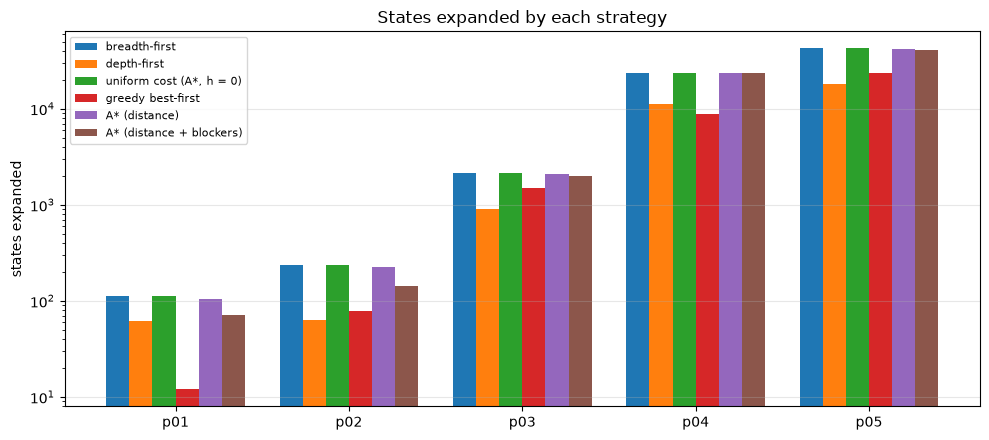

In [17]:
import matplotlib.pyplot as plt

solved = ["p01", "p02", "p03", "p04", "p05"]
names = list(STRATEGIES)
fig, ax = plt.subplots(figsize=(10, 4.5))
width = 0.8 / len(names)
for k in range(len(names)):
    xs = []
    ys = []
    for i in range(len(solved)):
        for (instance, name, number_of_moves, expanded, discovered, t) in results_slide:
            if instance == solved[i] and name == names[k]:
                xs.append(i + k * width)
                ys.append(expanded)
    ax.bar(xs, ys, width, label=names[k])
tick_positions = []
for i in range(len(solved)):
    tick_positions.append(i + 0.4 - width / 2)
ax.set_xticks(tick_positions)
ax.set_xticklabels(solved)
ax.set_yscale("log")
ax.set_ylabel("states expanded")
ax.set_title("States expanded by each strategy")
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("lab4_expanded.png", dpi=110)
plt.show()

## 9. p06 has no solution

Every strategy stops with an empty frontier after expanding the same 833 states: all the states reachable
from the initial board have been visited and none of them has the target on the exit. Below, the positions that
the target can reach: it never gets to the bottom row in the middle (top-left (2, 1)).

In [18]:
p06 = problems[5]
seen = set()
seen.add(p06.start)
todo = [p06.start]
while len(todo) > 0:
    s = todo.pop()
    for t in moves(s, p06):
        if t not in seen:
            seen.add(t)
            todo.append(t)
target_positions = set()
for s in seen:
    target_positions.add(target_pos(s))
print("reachable states:", len(seen))
print("positions reached by the target (top-left):", sorted(target_positions))
print("goal position:", target_goal(p06))

reachable states: 833
positions reached by the target (top-left): [(0, 0), (0, 1), (0, 2), (1, 1), (1, 2), (2, 2)]
goal position: (2, 1)
